# Project 13: CNN Architecture Comparison

**Course:** Deep Learning

## Objective
Compare two Convolutional Neural Network (CNN) architectures on the same image dataset and understand how depth and structure affect image-classification performance.

## Models
1. **Simple CNN:** Two convolutional layers followed by pooling and dense classification layers.
2. **VGG-style CNN:** A deeper, VGG-inspired model with stacked convolutional layers in blocks. This is a compact VGG-style design, not the original VGG16/VGG19.

## Dataset and evaluation
Both models use the MNIST handwritten digit dataset and the same preprocessing, training set, test set, optimizer, batch size, and epoch count. The comparison includes test accuracy, test loss, trainable parameters, training time, confusion matrices, and classification reports.

## 1. Import libraries
TensorFlow/Keras is used for the models, Matplotlib for plots, and scikit-learn for evaluation metrics.

In [1]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_recall_fscore_support, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Load and preprocess the dataset

MNIST contains grayscale handwritten digits from 0 to 9. Pixel values are normalized from 0–255 to 0–1, and a channel dimension is added for CNN input.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
Training labels: (60000,)
Test images: (10000, 28, 28, 1)
Test labels: (10000,)


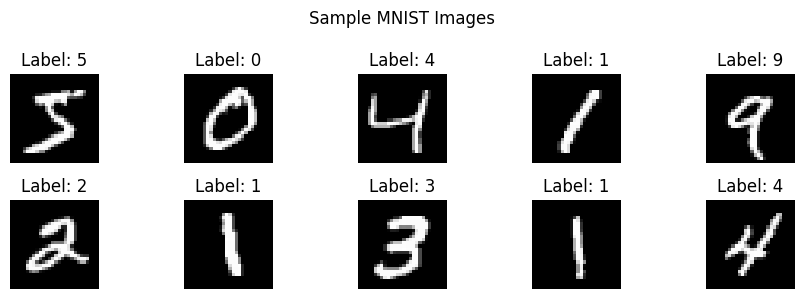

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)
class_names = [str(i) for i in range(10)]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

plt.figure(figsize=(9, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

## 3. Build Model 1: Simple CNN

The Simple CNN has two convolutional layers. Max pooling reduces spatial dimensions, and dense layers use the extracted features to classify each image as one of the ten digits.

In [3]:
def build_simple_cnn(input_shape=(28, 28, 1), num_classes=10):
    model = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.25),
        layers.Dense(num_classes, activation="softmax")
    ], name="Simple_CNN")
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

simple_cnn = build_simple_cnn()
simple_cnn.summary()

Model: "Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Build Model 2: VGG-style CNN

The deeper model uses two convolutional layers per block, with max pooling after each block. Stacking convolutions allows it to learn increasingly complex patterns. This small design is VGG-inspired, not the full VGG16/VGG19 architecture.

In [4]:
def build_vgg_style_cnn(input_shape=(28, 28, 1), num_classes=10):
    inputs = keras.Input(shape=input_shape)

    # Block 1
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2)(x)

    # Block 2
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2)(x)

    # Classification head
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="VGG_Style_CNN")
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

vgg_style_cnn = build_vgg_style_cnn()
vgg_style_cnn.summary()

Model: "VGG_Style_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 467,818 (1.78 MB)

 Trainable params: 467,818 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train both models

Both models use the same training set, validation split, optimizer, loss function, batch size, and epoch count. Three epochs are used as a quick baseline; increase `EPOCHS` if more training time is available. The notebook measures real results when executed, rather than assuming fixed accuracy values.

In [5]:
EPOCHS = 3
BATCH_SIZE = 128
training_results = {}

def train_model(model, label):
    print(f"Training {label}...")
    start = time.time()
    history = model.fit(
        x_train, y_train,
        validation_split=0.1,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )
    elapsed = time.time() - start
    print(f"{label} training time: {elapsed:.2f} seconds")
    return history, elapsed

simple_history, simple_time = train_model(simple_cnn, "Simple CNN")
vgg_history, vgg_time = train_model(vgg_style_cnn, "VGG-style CNN")

training_results = {
    "Simple CNN": {"model": simple_cnn, "history": simple_history, "time": simple_time},
    "VGG-style CNN": {"model": vgg_style_cnn, "history": vgg_history, "time": vgg_time}
}

Training Simple CNN...
Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 76s 167ms/step - accuracy: 0.9150 - loss: 0.2846 - val_accuracy: 0.9825 - val_loss: 0.0614
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 66s 131ms/step - accuracy: 0.9738 - loss: 0.0868 - val_accuracy: 0.9862 - val_loss: 0.0508
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 128ms/step - accuracy: 0.9808 - loss: 0.0629 - val_accuracy: 0.9885 - val_loss: 0.0409
Simple CNN training time: 223.20 seconds
Training VGG-style CNN...
Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 186s 437ms/step - accuracy: 0.9317 - loss: 0.2170 - val_accuracy: 0.9862 - val_loss: 0.0464
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 183s 434ms/step - accuracy: 0.9811 - loss: 0.0616 - val_accuracy: 0.9880 - val_loss: 0.0407
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 187s 444ms/step - accuracy: 0.9871 - loss: 0.0417 - val_accuracy: 0.9918 - val_loss: 0.0287
VGG-style CNN training time: 557.26 seconds


## 6. Compare training and validation curves
Accuracy indicates classification performance during training; loss indicates the model's prediction error. Validation metrics are calculated on data not used to update model weights.

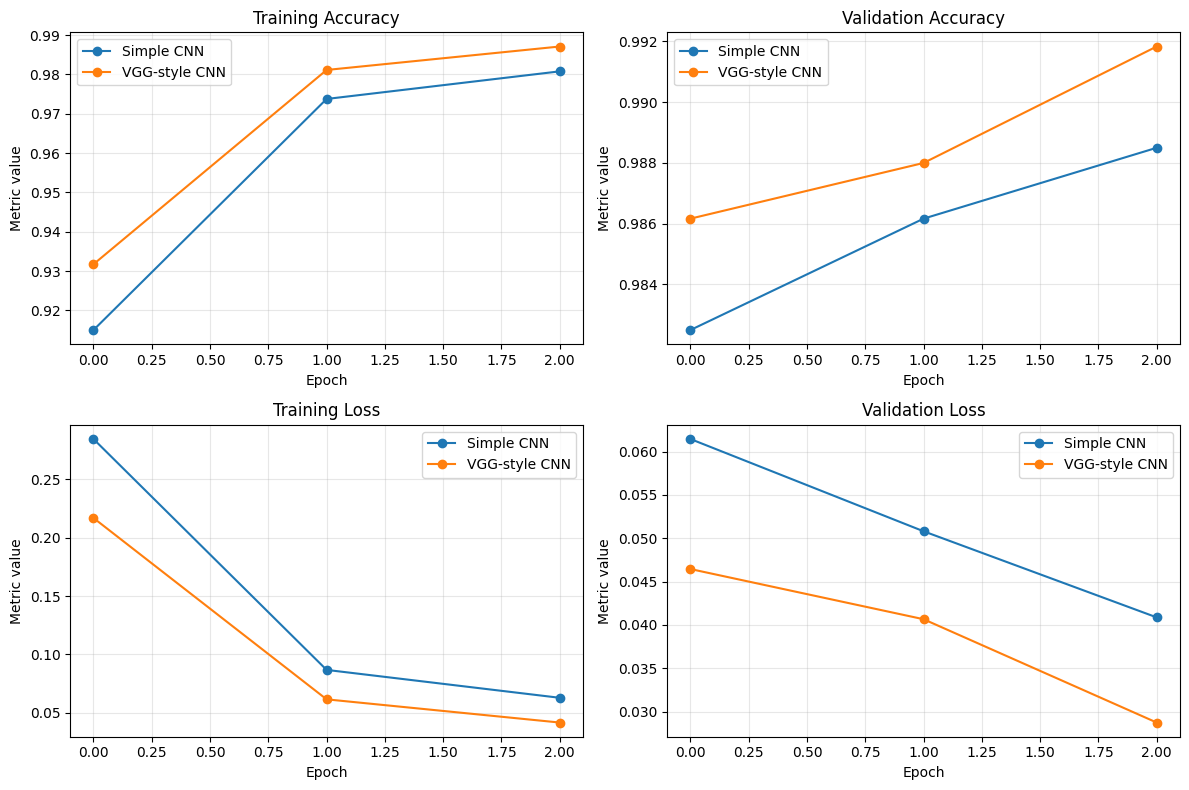

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for label, result in training_results.items():
    h = result["history"].history
    axes[0, 0].plot(h["accuracy"], marker="o", label=label)
    axes[0, 1].plot(h["val_accuracy"], marker="o", label=label)
    axes[1, 0].plot(h["loss"], marker="o", label=label)
    axes[1, 1].plot(h["val_loss"], marker="o", label=label)

axes[0, 0].set_title("Training Accuracy")
axes[0, 1].set_title("Validation Accuracy")
axes[1, 0].set_title("Training Loss")
axes[1, 1].set_title("Validation Loss")
for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Metric value")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Evaluate on the same test set
Test accuracy and loss measure performance on the held-out MNIST test set. Trainable parameters indicate model size; training time indicates observed computational cost.

In [7]:
evaluation_rows = []
predictions = {}

for label, result in training_results.items():
    model = result["model"]
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
    probabilities = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)
    predictions[label] = y_pred
    trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))

    evaluation_rows.append({
        "Model": label,
        "Test Accuracy (%)": round(float(test_accuracy) * 100, 2),
        "Test Loss": round(float(test_loss), 4),
        "Trainable Parameters": trainable_params,
        "Training Time (seconds)": round(result["time"], 2)
    })

comparison_df = pd.DataFrame(evaluation_rows)
comparison_df

,Model,Test Accuracy (%),Test Loss,Trainable Parameters,Training Time (seconds)
0,Simple CNN,98.71,0.0375,220234,223.20
1,VGG-style CNN,99.13,0.0251,467818,557.26


## 8. Confusion matrices

Correct predictions appear on the main diagonal. Off-diagonal cells show digits that the model misclassified.

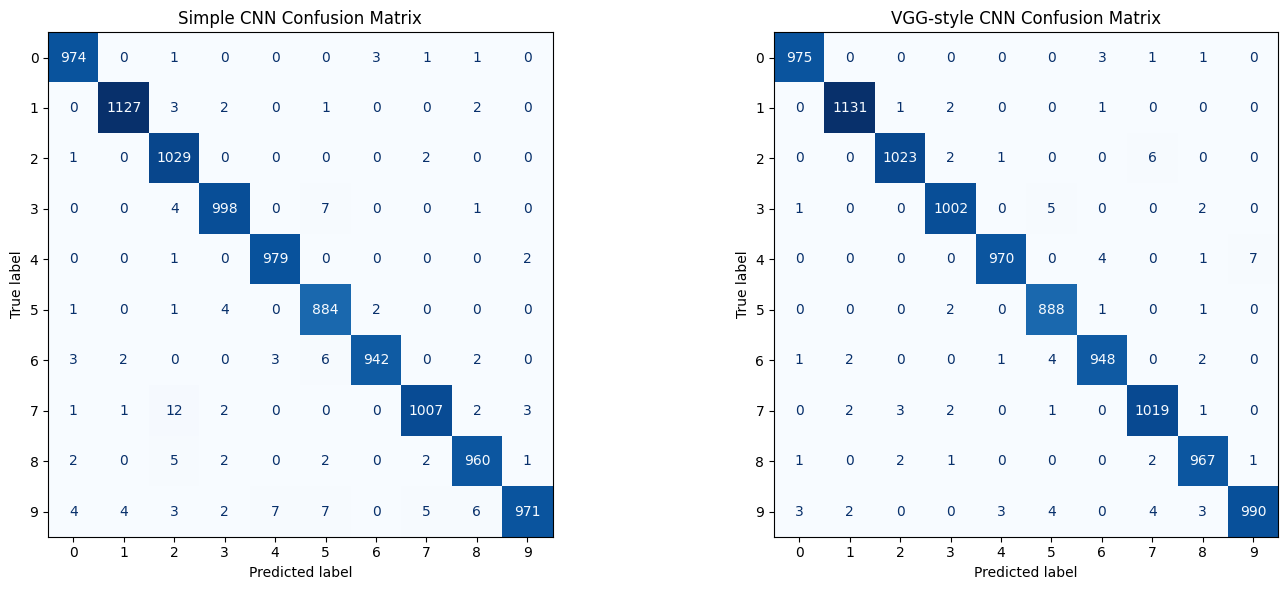

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, label in zip(axes, ["Simple CNN", "VGG-style CNN"]):
    cm = confusion_matrix(y_test, predictions[label], labels=np.arange(10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{label} Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Classification reports

Precision shows how often a model's predictions for a class are correct. Recall measures how many actual examples of that class are identified. The F1-score balances precision and recall; support is the number of test examples for each digit.

In [9]:
for label in ["Simple CNN", "VGG-style CNN"]:
    print("\\n" + "=" * 65)
    print(f"Classification Report: {label}")
    print("=" * 65)
    print(classification_report(
        y_test, predictions[label],
        labels=np.arange(10),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

\n=================================================================
Classification Report: Simple CNN
              precision    recall  f1-score   support

           0     0.9878    0.9939    0.9908       980
           1     0.9938    0.9930    0.9934      1135
           2     0.9717    0.9971    0.9842      1032
           3     0.9881    0.9881    0.9881      1010
           4     0.9899    0.9969    0.9934       982
           5     0.9746    0.9910    0.9828       892
           6     0.9947    0.9833    0.9890       958
           7     0.9902    0.9796    0.9848      1028
           8     0.9856    0.9856    0.9856       974
           9     0.9939    0.9623    0.9778      1009

    accuracy                         0.9871     10000
   macro avg     0.9870    0.9871    0.9870     10000
weighted avg     0.9872    0.9871    0.9871     10000

\n=================================================================
Classification Report: VGG-style CNN
              precision    recall 

## 10. Compare precision, recall, and F1-score
Macro averages give every digit equal weight, making them useful alongside overall accuracy.

In [10]:
summary_rows = []
for label in ["Simple CNN", "VGG-style CNN"]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions[label], average="macro", zero_division=0
    )
    summary_rows.append({
        "Model": label,
        "Accuracy (%)": round(accuracy_score(y_test, predictions[label]) * 100, 2),
        "Macro Precision": round(float(precision), 4),
        "Macro Recall": round(float(recall), 4),
        "Macro F1-score": round(float(f1), 4)
    })
metrics_df = pd.DataFrame(summary_rows)
metrics_df

,Model,Accuracy (%),Macro Precision,Macro Recall,Macro F1-score
0,Simple CNN,98.71,0.9870,0.9871,0.9870
1,VGG-style CNN,99.13,0.9912,0.9913,0.9912


## 11. Final comparison

This cell summarizes the actual results produced by the executed notebook. A deeper model is not guaranteed to have higher accuracy in a short experiment; training duration and initialization can affect the outcome.

In [11]:
simple_row = comparison_df.loc[comparison_df["Model"] == "Simple CNN"].iloc[0]
vgg_row = comparison_df.loc[comparison_df["Model"] == "VGG-style CNN"].iloc[0]

print("FINAL COMPARISON")
print("-" * 50)
print(f"Simple CNN test accuracy: {simple_row['Test Accuracy (%)']}%")
print(f"VGG-style CNN test accuracy: {vgg_row['Test Accuracy (%)']}%")
print(f"Simple CNN parameters: {simple_row['Trainable Parameters']:,}")
print(f"VGG-style CNN parameters: {vgg_row['Trainable Parameters']:,}")
print(f"Simple CNN training time: {simple_row['Training Time (seconds)']} seconds")
print(f"VGG-style CNN training time: {vgg_row['Training Time (seconds)']} seconds")

difference = vgg_row["Test Accuracy (%)"] - simple_row["Test Accuracy (%)"]
ratio = vgg_row["Trainable Parameters"] / simple_row["Trainable Parameters"]
if difference > 0:
    print(f"VGG-style CNN achieved {difference:.2f} percentage points higher test accuracy.")
elif difference < 0:
    print(f"Simple CNN achieved {abs(difference):.2f} percentage points higher test accuracy.")
else:
    print("Both models achieved the same test accuracy to two decimal places.")
print(f"VGG-style CNN has about {ratio:.2f} times as many trainable parameters.")

FINAL COMPARISON
--------------------------------------------------
Simple CNN test accuracy: 98.71%
VGG-style CNN test accuracy: 99.13%
Simple CNN parameters: 220,234
VGG-style CNN parameters: 467,818
Simple CNN training time: 223.2 seconds
VGG-style CNN training time: 557.26 seconds
VGG-style CNN achieved 0.42 percentage points higher test accuracy.
VGG-style CNN has about 2.12 times as many trainable parameters.


## Results, observations, and conclusion

### Key observations
- Both models use the same normalized MNIST data and the same held-out test set, making their results comparable.
- The Simple CNN is a lightweight baseline with fewer convolutional layers.
- The VGG-style CNN stacks convolutional layers in blocks to learn more layered image features.
- Accuracy and classification reports measure predictive performance, while parameter count and training time measure aspects of complexity and cost.
- Confusion matrices reveal the digit classes that each model tends to mix up.

### Conclusion
This experiment compares a Simple CNN with a deeper VGG-style CNN for handwritten digit classification. It demonstrates how architecture can affect feature extraction, accuracy, prediction errors, model size, and training cost. The preferred model should be selected using the measured results and resource requirements, not depth alone.

